# Brain Tumor Classification (MRI)

Classify brain MRI images into four classes: **glioma**, **meningioma**, **pituitary** tumor, or **no tumor**.

- Dataset: [Brain Tumor Classification (MRI)](https://www.kaggle.com/datasets/sartajbhuvaji/brain-tumor-classification-mri) by Sartaj Bhuvaji
- Model: MobileNetV2 (pretrained on ImageNet) + a small classification head
- Framework: TensorFlow / Keras

> Turn on a GPU first: **Runtime → Change runtime type → T4 GPU**.

*Educational project only. Not for medical use.*

## 1. Setup

In [ ]:
!pip install -q kagglehub

import os, glob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix
import kagglehub

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download the dataset

In [ ]:
path = kagglehub.dataset_download("sartajbhuvaji/brain-tumor-classification-mri")

train_dir = glob.glob(os.path.join(path, "**", "Training"), recursive=True)[0]
test_dir  = glob.glob(os.path.join(path, "**", "Testing"),  recursive=True)[0]

print("Train folder:", train_dir)
print("Test folder: ", test_dir)
for split_dir in (train_dir, test_dir):
    print("\n", os.path.basename(split_dir))
    for c in sorted(os.listdir(split_dir)):
        print(f"  {c:20s} {len(os.listdir(os.path.join(split_dir, c)))} images")

Using Colab cache for faster access to the 'brain-tumor-classification-mri' dataset.
Train folder: /kaggle/input/brain-tumor-classification-mri/Training
Test folder:  /kaggle/input/brain-tumor-classification-mri/Testing

 Training
  glioma_tumor         826 images
  meningioma_tumor     822 images
  no_tumor             395 images
  pituitary_tumor      827 images

 Testing
  glioma_tumor         100 images
  meningioma_tumor     115 images
  no_tumor             105 images
  pituitary_tumor      74 images


## 3. Load the data
We hold out 20% of the training images for validation. The `Testing` folder is only used at the very end.

In [ ]:
IMG_SIZE = (224, 224)
BATCH = 32
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="training",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH)

val_ds = keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="validation",
    seed=SEED, image_size=IMG_SIZE, batch_size=BATCH)

test_ds = keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 2870 files belonging to 4 classes.
Using 2296 files for training.
Found 2870 files belonging to 4 classes.
Using 574 files for validation.
Found 394 files belonging to 4 classes.
Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


## 4. Look at some images

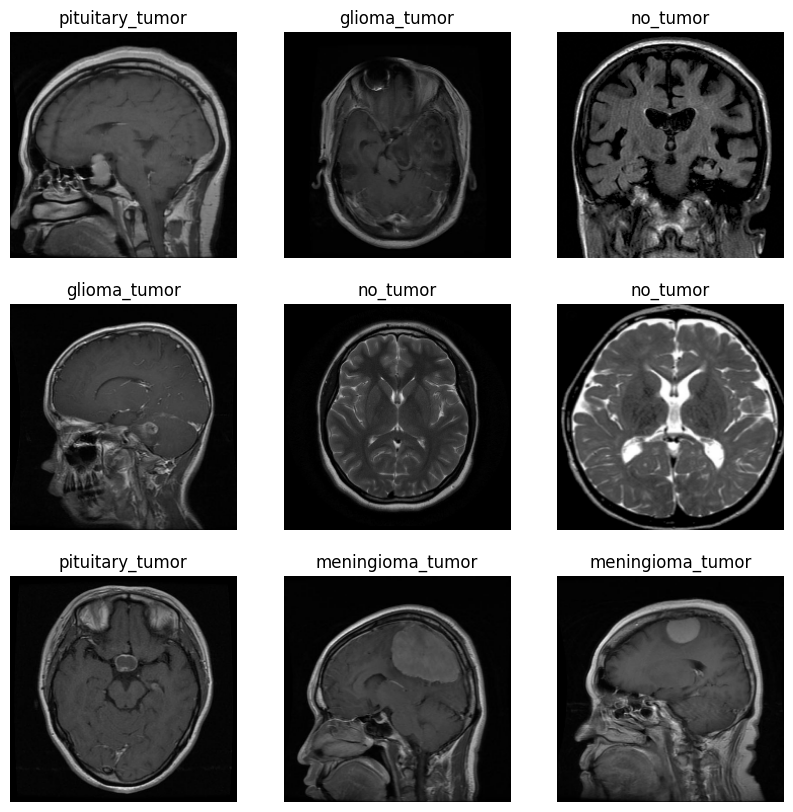

In [ ]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

## 5. Build the model

In [ ]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
])

base = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False   # keep pretrained weights frozen

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Train

In [ ]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

history = model.fit(train_ds, validation_data=val_ds,
                    epochs=15, callbacks=[early_stop])

Epoch 1/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 28s 237ms/step - accuracy: 0.6159 - loss: 0.9333 - val_accuracy: 0.7369 - val_loss: 0.6671
Epoch 2/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 94ms/step - accuracy: 0.7591 - loss: 0.6138 - val_accuracy: 0.7840 - val_loss: 0.5610
Epoch 3/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 82ms/step - accuracy: 0.7988 - loss: 0.5219 - val_accuracy: 0.7613 - val_loss: 0.6065
Epoch 4/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 0.8179 - loss: 0.4839 - val_accuracy: 0.7892 - val_loss: 0.5606
Epoch 5/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 76ms/step - accuracy: 0.8267 - loss: 0.4459 - val_accuracy: 0.8118 - val_loss: 0.4881
Epoch 6/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 0.8297 - loss: 0.4065 - val_accuracy: 0.7944 - val_loss: 0.5344
Epoch 7/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 10s 82ms/step - accuracy: 0.8454 - loss: 0.3996 - val_accuracy: 0.8014 - val_loss: 0.5024
Epoch 8/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 90ms/step - accuracy: 0.8541 - loss: 0.3841 - val_accuracy: 0.8101 

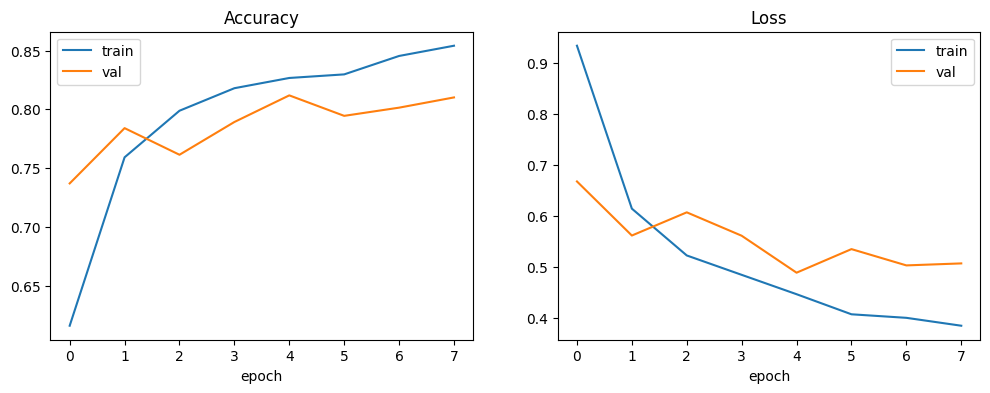

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.show()

In [ ]:
# Unfreeze the last 40 layers of MobileNetV2 and train with a small learning rate
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history_ft = model.fit(train_ds, validation_data=val_ds,
                       epochs=15, callbacks=[early_stop])

Epoch 1/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 24s 129ms/step - accuracy: 0.6071 - loss: 1.1734 - val_accuracy: 0.8345 - val_loss: 0.4599
Epoch 2/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 90ms/step - accuracy: 0.7875 - loss: 0.6292 - val_accuracy: 0.8223 - val_loss: 0.4902
Epoch 3/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 11s 94ms/step - accuracy: 0.8349 - loss: 0.4780 - val_accuracy: 0.8171 - val_loss: 0.5093
Epoch 4/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 102ms/step - accuracy: 0.8515 - loss: 0.3917 - val_accuracy: 0.8275 - val_loss: 0.5064


In [ ]:
print("train:", model.evaluate(train_ds, verbose=0)[1])
print("val:  ", model.evaluate(val_ds, verbose=0)[1])
print("test: ", model.evaluate(test_ds, verbose=0)[1])

train: 0.861498236656189
val:   0.8344947695732117
test:  0.5888324975967407


## 7. Evaluate on the test set

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.5888 - loss: 1.5137
Test accuracy: 0.589
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step
                  precision    recall  f1-score   support

    glioma_tumor       0.58      0.19      0.29       100
meningioma_tumor       0.50      0.50      0.50       115
        no_tumor       0.55      0.97      0.71       105
 pituitary_tumor       0.84      0.73      0.78        74

        accuracy                           0.59       394
       macro avg       0.62      0.60      0.57       394
    weighted avg       0.60      0.59      0.55       394



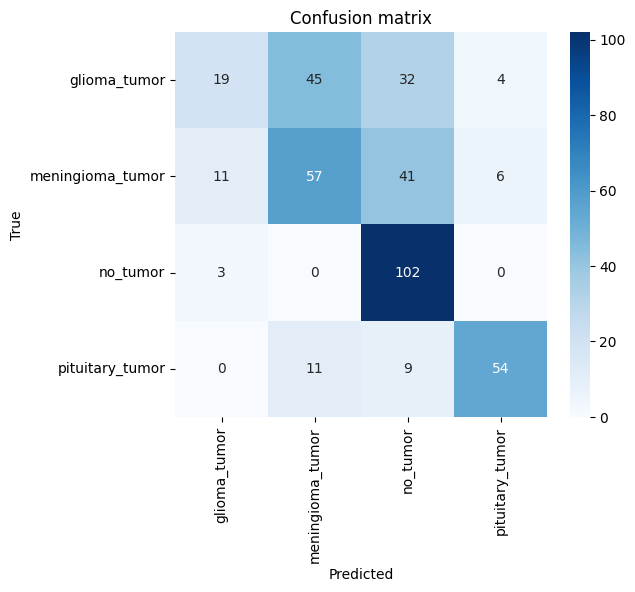

In [ ]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.3f}")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix")
plt.show()

In [ ]:
print("train:", model.evaluate(train_ds, verbose=0)[1])
print("val:  ", model.evaluate(val_ds, verbose=0)[1])
print("test: ", model.evaluate(test_ds, verbose=0)[1])

train: 0.861498236656189
val:   0.8344947695732117
test:  0.5888324975967407


## 8. Try some predictions

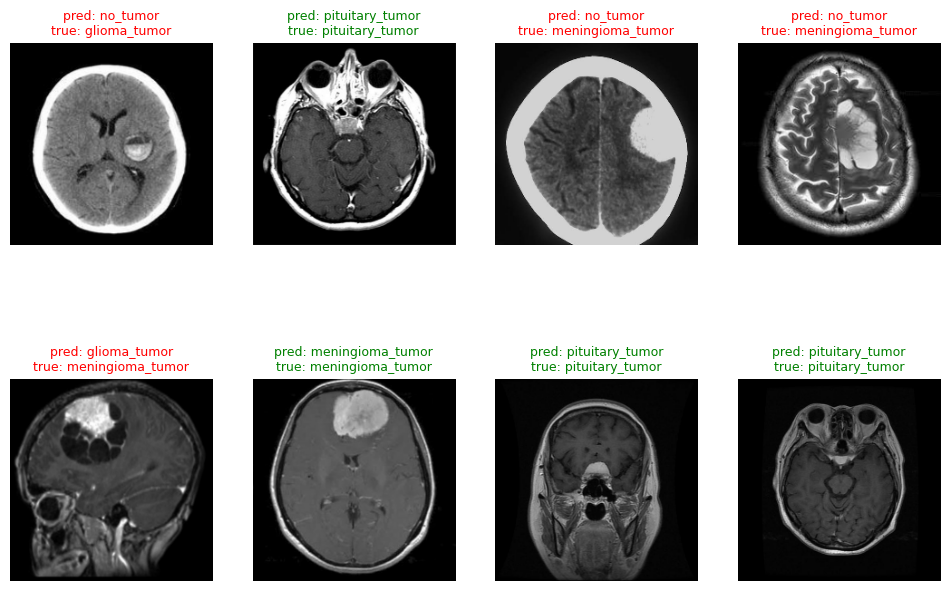

In [ ]:
plt.figure(figsize=(12, 8))
for images, labels in test_ds.unbatch().shuffle(400, seed=1).batch(8).take(1):
    probs = model.predict(images, verbose=0)
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        pred = class_names[np.argmax(probs[i])]
        true = class_names[labels[i]]
        plt.title(f"pred: {pred}\ntrue: {true}",
                  color="green" if pred == true else "red", fontsize=9)
        plt.axis("off")
plt.show()

In [ ]:
model.save("brain_tumor_model.keras")

Saving Screenshot 2026-11-15 155018.png to Screenshot 2026-11-15 155018.png
Screenshot 2026-11-15 155018.png
  glioma_tumor       0.0%
  meningioma_tumor   38.8%
  no_tumor           61.1%
  pituitary_tumor    0.1%


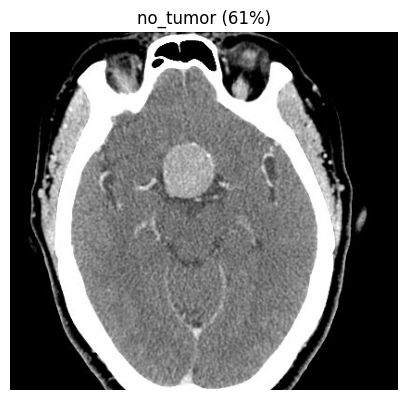

In [ ]:
from google.colab import files
from PIL import Image

uploaded = files.upload()   # pick one or more MRI images

resize = layers.Resizing(224, 224, crop_to_aspect_ratio=True)

plt.figure(figsize=(5 * len(uploaded), 5))
for i, name in enumerate(uploaded):
    img = Image.open(name).convert("RGB")
    x = resize(np.array(img)[None, ...].astype("float32"))   # shape (1, 224, 224, 3)

    probs = model.predict(x, verbose=0)[0]
    pred = class_names[np.argmax(probs)]

    plt.subplot(1, len(uploaded), i + 1)
    plt.imshow(img)
    plt.title(f"{pred} ({probs.max():.0%})")
    plt.axis("off")

    print(name)
    for c, p in zip(class_names, probs):
        print(f"  {c:18s} {p:.1%}")
plt.show()